In [1]:
import os

for root, dirs, files in os.walk("/opt/spark/python"):
    for f in files:
        if "py4j" in f:
            print(os.path.join(root, f))

/opt/spark/python/lib/py4j-0.10.9.9-src.zip


In [2]:
import sys
import glob

sys.path.insert(0, "/opt/spark/python")

py4j_path = glob.glob("/opt/spark/python/lib/py4j*.zip")[0]
sys.path.insert(0, py4j_path)

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Amazon Video Games") \
    .master("local[*]") \
    .getOrCreate()

print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/02 14:05:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.0


In [3]:
reviews = spark.read.json(
    "hdfs://namenode:9000/data/amazon_reviews/reviews.json"
)

reviews.show(5)

+----------+-----+-------+--------------------+-----------+--------------+----------------+-----+--------------------+--------------+--------+----+
|      asin|image|overall|          reviewText| reviewTime|    reviewerID|    reviewerName|style|             summary|unixReviewTime|verified|vote|
+----------+-----+-------+--------------------+-----------+--------------+----------------+-----+--------------------+--------------+--------+----+
|0439381673| NULL|    1.0|I used to play th...| 06 9, 2014|A21ROB4YDOZA5P|   Mary M. Clark| NULL|   Did not like this|    1402272000|    true|NULL|
|0439381673| NULL|    3.0|The game itself w...|05 10, 2014|A3TNZ2Q5E7HTHD|       Sarabatya| NULL|      Almost Perfect|    1399680000|    true|NULL|
|0439381673| NULL|    4.0|I had to learn th...| 02 7, 2014|A1OKRM3QFEATQO| Amazon Customer| NULL|DOES NOT WORK WIT...|    1391731200|    true|  15|
|0439381673| NULL|    1.0|The product descr...| 02 7, 2014|A2XO1JFCNEYV3T|ColoradoPartyof5| NULL|does not work o

In [7]:
review_with_image = reviews.filter(
    col("vote").isNotNull()
)

review_with_image.show(5)

+----------+-----+-------+--------------------+-----------+--------------+----------------+-----+--------------------+--------------+--------+----+
|      asin|image|overall|          reviewText| reviewTime|    reviewerID|    reviewerName|style|             summary|unixReviewTime|verified|vote|
+----------+-----+-------+--------------------+-----------+--------------+----------------+-----+--------------------+--------------+--------+----+
|0439381673| NULL|    4.0|I had to learn th...| 02 7, 2014|A1OKRM3QFEATQO| Amazon Customer| NULL|DOES NOT WORK WIT...|    1391731200|    true|  15|
|0439381673| NULL|    1.0|The product descr...| 02 7, 2014|A2XO1JFCNEYV3T|ColoradoPartyof5| NULL|does not work on ...|    1391731200|    true|  11|
|0439381673| NULL|    5.0|Choose your caree...| 01 7, 2014|A1TLA7XXSZMTS7|      lori smith| NULL|Love this game!  ...|    1389052800|    true|   2|
|0439381673| NULL|    3.0|Would like it mor...|10 22, 2013|A3I9GK5OO42B0I|   Edwin Grabill| NULL|Would like it m

In [4]:
metadata = spark.read.json(
    "hdfs://namenode:9000/data/amazon_reviews/metadata.json"
)

metadata.show(5)

+------------+--------------------+----------+--------------------+--------------------+----+--------------------+-------+--------------------+---+--------------------+--------------------+----------------+--------------------+--------------------+------------+-----+-----+--------------------+
|    also_buy|           also_view|      asin|               brand|            category|date|         description|details|             feature|fit|            imageURL|     imageURLHighRes|        main_cat|               price|                rank|similar_item|tech1|tech2|               title|
+------------+--------------------+----------+--------------------+--------------------+----+--------------------+-------+--------------------+---+--------------------+--------------------+----------------+--------------------+--------------------+------------+-----+-----+--------------------+
|          []|                  []|0042000742|Fidelity Electronics|[Video Games, PC,...|    |                  []| 

In [5]:
print("Reviews:", reviews.count())
print("Metadata:", metadata.count())

26/10/01 04:42:46 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Reviews: 2565349
Metadata: 84819


In [8]:
reviews.printSchema()

root
 |-- asin: string (nullable = true)
 |-- image: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- overall: double (nullable = true)
 |-- reviewText: string (nullable = true)
 |-- reviewTime: string (nullable = true)
 |-- reviewerID: string (nullable = true)
 |-- reviewerName: string (nullable = true)
 |-- style: struct (nullable = true)
 |    |-- Color Name:: string (nullable = true)
 |    |-- Color:: string (nullable = true)
 |    |-- Configuration:: string (nullable = true)
 |    |-- Content:: string (nullable = true)
 |    |-- Denomination:: string (nullable = true)
 |    |-- Edition:: string (nullable = true)
 |    |-- Format:: string (nullable = true)
 |    |-- Item Package Quantity:: string (nullable = true)
 |    |-- Length:: string (nullable = true)
 |    |-- Offer Type:: string (nullable = true)
 |    |-- Package Quantity:: string (nullable = true)
 |    |-- Package Type:: string (nullable = true)
 |    |-- Pattern:: string (nullable = true)
 | 

In [9]:
reviews.columns

['asin',
 'image',
 'overall',
 'reviewText',
 'reviewTime',
 'reviewerID',
 'reviewerName',
 'style',
 'summary',
 'unixReviewTime',
 'verified',
 'vote']

In [5]:
metadata.printSchema()

root
 |-- also_buy: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- also_view: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- asin: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- category: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- date: string (nullable = true)
 |-- description: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- details: struct (nullable = true)
 |    |-- \n    Item Weight: \n    : string (nullable = true)
 |    |-- \n    Package Dimensions: \n    : string (nullable = true)
 |    |-- \n    Product Dimensions: \n    : string (nullable = true)
 |    |--  Date first listed on Amazon:: string (nullable = true)
 |    |-- ASIN:: string (nullable = true)
 |    |-- ASIN: : string (nullable = true)
 |    |-- Audio CD: string (nullable = true)
 |    |-- Batteries: string (nullable = true)
 |    |-- CD-ROM:: string (nullable = true)
 |    |--

In [5]:
from pyspark.sql.functions import col

invalid_rating = reviews.filter(
    (col("overall") < 1) | 
    (col("overall") > 5) |
    col("overall").isNull()
)

invalid_rating.count()

0

In [11]:
metadata.columns

['also_buy',
 'also_view',
 'asin',
 'brand',
 'category',
 'date',
 'description',
 'details',
 'feature',
 'fit',
 'imageURL',
 'imageURLHighRes',
 'main_cat',
 'price',
 'rank',
 'similar_item',
 'tech1',
 'tech2',
 'title']

In [12]:
metadata_filter = metadata.filter(
    col("feature").isNotNull()
)

metadata_filter.show(5)

+------------+--------------------+----------+--------------------+--------------------+----+--------------------+-------+--------------------+---+--------------------+--------------------+----------------+--------------------+--------------------+------------+-----+-----+--------------------+
|    also_buy|           also_view|      asin|               brand|            category|date|         description|details|             feature|fit|            imageURL|     imageURLHighRes|        main_cat|               price|                rank|similar_item|tech1|tech2|               title|
+------------+--------------------+----------+--------------------+--------------------+----+--------------------+-------+--------------------+---+--------------------+--------------------+----------------+--------------------+--------------------+------------+-----+-----+--------------------+
|          []|                  []|0042000742|Fidelity Electronics|[Video Games, PC,...|    |                  []| 

In [14]:
reviews.show(5, truncate=False)

+----------+-----+-------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----------+--------------+----------------+-----+-----------------------------------------------------------+--------------+--------+----+
|asin      |image|overall|reviewText                                                                                                                                                                                                                                                                                                                                                              

In [15]:
metadata.show(5, truncate=False)

+------------+------------------------------------------------------------------------+----------+-----------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [16]:
# Rating Distribution

from pyspark.sql.functions import count

rating_dist = reviews.groupBy("overall") \
    .agg(count("*").alias("total")) \
    .orderBy("overall")

rating_dist.show()

[Stage 18:===>                                                    (1 + 15) / 16]

+-------+-------+
|overall|  total|
+-------+-------+
|    1.0| 311891|
|    2.0| 141333|
|    3.0| 212346|
|    4.0| 412413|
|    5.0|1487366|
+-------+-------+



In [17]:
# Missing Value

from pyspark.sql.functions import col, sum

important_cols = [
    "asin",
    "overall",
    "reviewText",
    "reviewerID"
]

missing_reviews = reviews.select(
    [
        sum(col(c).isNull().cast("int")).alias(c)
        for c in important_cols
    ]
)

missing_reviews.show()

[Stage 21:=============================================>          (13 + 3) / 16]

+----+-------+----------+----------+
|asin|overall|reviewText|reviewerID|
+----+-------+----------+----------+
|   0|      0|      1715|         0|
+----+-------+----------+----------+



In [18]:
reviews.select("asin").distinct().count()

71982

In [19]:
metadata.select("asin").distinct().count()

71911

In [20]:
reviews.select("reviewerID").distinct().count()

1540618

In [21]:
reviews.groupBy("verified") \
    .count() \
    .show()

[Stage 42:========================>                                (7 + 9) / 16]

+--------+-------+
|verified|  count|
+--------+-------+
|    true|1948309|
|   false| 617040|
+--------+-------+



In [22]:
metadata.select(
    "asin",
    "title",
    "brand"
).show(10, truncate=False)

+----------+--------------------------------------------------------------------------+-----------------------------------------+
|asin      |title                                                                     |brand                                    |
+----------+--------------------------------------------------------------------------+-----------------------------------------+
|0042000742|Reversi Sensory Challenger                                                |Fidelity Electronics                     |
|0078764343|Medal of Honor: Warfighter - Includes Battlefield 4 Beta - Limited Edition|by\n    \n    EA Games                   |
|0276425316|street fighter 2 II turbo super nintendo snes super nes video game        |Nintendo                                 |
|0324411812|Xbox 360 MAS STICK                                                        |by\n    \n    MAS SYSTEMS                |
|0439335310|Phonics Alive! 3: The Speller                                             |by\

In [23]:
from pyspark.sql.functions import col

reviews_columns = reviews.columns

print("Jumlah kolom reviews:", len(reviews_columns))

for c in reviews_columns:
    print(c)

Jumlah kolom reviews: 12
asin
image
overall
reviewText
reviewTime
reviewerID
reviewerName
style
summary
unixReviewTime
verified
vote


In [24]:
print("Jumlah kolom metadata:", len(metadata.columns))

for c in metadata.columns:
    print(c)

Jumlah kolom metadata: 19
also_buy
also_view
asin
brand
category
date
description
details
feature
fit
imageURL
imageURLHighRes
main_cat
price
rank
similar_item
tech1
tech2
title


In [25]:
from pyspark.sql.functions import count, avg

rating_stats = reviews.groupBy("overall") \
    .agg(count("*").alias("total")) \
    .orderBy("overall")

rating_stats.show()

[Stage 46:>                                                       (0 + 16) / 16]

+-------+-------+
|overall|  total|
+-------+-------+
|    1.0| 311891|
|    2.0| 141333|
|    3.0| 212346|
|    4.0| 412413|
|    5.0|1487366|
+-------+-------+



In [26]:
total_reviews = reviews.count()

rating_distribution = rating_stats.withColumn(
    "percentage",
    (col("total") / total_reviews * 100)
)

rating_distribution.show()

+-------+-------+------------------+
|overall|  total|        percentage|
+-------+-------+------------------+
|    1.0| 311891|12.157838952906602|
|    2.0| 141333|5.5093088698652695|
|    3.0| 212346| 8.277470238942147|
|    4.0| 412413|16.076292153621203|
|    5.0|1487366| 57.97908978466477|
+-------+-------+------------------+



In [27]:
from pyspark.sql.functions import sum

def missing_values(df):
    return df.select([
        sum(col(c).isNull().cast("int")).alias(c)
        for c in df.columns
    ])

missing_values(reviews).show()

[Stage 55:====================================================>   (15 + 1) / 16]

+----+-------+-------+----------+----------+----------+------------+-------+-------+--------------+--------+-------+
|asin|  image|overall|reviewText|reviewTime|reviewerID|reviewerName|  style|summary|unixReviewTime|verified|   vote|
+----+-------+-------+----------+----------+----------+------------+-------+-------+--------------+--------+-------+
|   0|2537044|      0|      1715|         0|         0|         253|1245377|    811|             0|       0|2122633|
+----+-------+-------+----------+----------+----------+------------+-------+-------+--------------+--------+-------+



In [28]:
print("Unique products in reviews:",
      reviews.select("asin").distinct().count())

print("Unique products in metadata:",
      metadata.select("asin").distinct().count())

Unique products in reviews: 71982
Unique products in metadata: 71911


In [29]:
unique_reviewers = reviews.select("reviewerID") \
    .distinct() \
    .count()

print("Unique reviewers:", unique_reviewers)

[Stage 70:===================================>                    (10 + 6) / 16]

Unique reviewers: 1540618


In [30]:
from pyspark.sql.functions import length

review_length = reviews.withColumn(
    "review_length",
    length(col("reviewText"))
)

review_length.select(
    "review_length"
).describe().show()

[Stage 76:==========================================>             (12 + 4) / 16]

+-------+-----------------+
|summary|    review_length|
+-------+-----------------+
|  count|          2563634|
|   mean|401.0472458237018|
| stddev|811.3024772706987|
|    min|                1|
|    max|            32721|
+-------+-----------------+



In [31]:
top_products = reviews.groupBy("asin") \
    .count() \
    .orderBy(col("count").desc())

top_products.show(10)

[Stage 79:=================>                                      (5 + 11) / 16]

+----------+-----+
|      asin|count|
+----------+-----+
|B00178630A| 7630|
|B00HTK1NCS| 6462|
|B004RMK57U| 5135|
|B00KKAQYXM| 4359|
|B00JJNQG98| 3962|
|B003ZSP0WW| 3960|
|B000ZKA0J6| 3930|
|B000VJRU44| 3634|
|B00E4MQODC| 3520|
|B000B9RI14| 3345|
+----------+-----+
only showing top 10 rows


In [37]:
top_products.show(20)

[Stage 103:======>                                                (2 + 14) / 16]

+----------+-----+
|      asin|count|
+----------+-----+
|B00178630A| 7630|
|B00HTK1NCS| 6462|
|B004RMK57U| 5135|
|B00KKAQYXM| 4359|
|B00JJNQG98| 3962|
|B003ZSP0WW| 3960|
|B000ZKA0J6| 3930|
|B000VJRU44| 3634|
|B00E4MQODC| 3520|
|B000B9RI14| 3345|
|B0009VXBAQ| 3167|
|B00DBDPOZ4| 3162|
|B00BFOEY4I| 2990|
|B000HZFCT2| 2959|
|B000XJNTNS| 2952|
|B00MYTSDU4| 2928|
|B0050SYX8W| 2912|
|B00AAS888S| 2905|
|B000FO4KO8| 2879|
|B00CMN0Z0S| 2859|
+----------+-----+
only showing top 20 rows


In [38]:
top_products_name = top_products.join(
    metadata.select("asin","title"),
    "asin",
    "left"
).orderBy(
    col("count").desc()
)

top_products_name.show(10, truncate=False)

+----------+-----+------------------------------------------------------------------------------------------------------------------------------------------------------------+
|asin      |count|title                                                                                                                                                       |
+----------+-----+------------------------------------------------------------------------------------------------------------------------------------------------------------+
|B00178630A|7630 |Diablo III                                                                                                                                                  |
|B00HTK1NCS|6462 |Redragon M601 Wired Gaming Mouse, Ergonomic, Programmable 6 Buttons, 3200 DPI with Red LED Mouse for Windows PC Games - Black                               |
|B004RMK57U|5135 |Playstation Plus: 3 Month Membership [Digital Code]                                                   

In [33]:
from pyspark.sql.functions import count, col

duplicate_asin = metadata.groupBy("asin") \
    .count() \
    .filter(col("count") > 1)

print("Jumlah ASIN duplicate:")
print(duplicate_asin.count())

duplicate_asin.orderBy(
    col("count").desc()
).show(10)

Jumlah ASIN duplicate:
12908
+----------+-----+
|      asin|count|
+----------+-----+
|B00000K1XN|    2|
|B00001OX40|    2|
|B00001QEQD|    2|
|B00001XDTO|    2|
|B00001ZWQ0|    2|
|B00002SFMS|    2|
|B00002SSYX|    2|
|B00002STA7|    2|
|B00002STH3|    2|
|B00002STJC|    2|
+----------+-----+
only showing top 10 rows


In [40]:
missing_metadata_asin = reviews.select("asin") \
    .distinct() \
    .join(
        metadata.select("asin").distinct(),
        on="asin",
        how="left_anti"
    )

missing_metadata_asin.show(20)

[Stage 130:=============>                                         (4 + 12) / 16]

+----------+
|      asin|
+----------+
|B001AWOVA2|
|B00149ND28|
|B0014Y2TPK|
|B0016N50VY|
|B0016CP3B2|
|B0016BVYAM|
|B0018YDKAO|
|B0018YDK8Q|
|B0016HF8DA|
|B001ABLHJG|
|B001811BUI|
|B0018BEG96|
|B0016BVY8O|
|B001AMRR26|
|B00149PCAO|
|B001A35OG6|
|B001A1V22S|
|B0017ZK7PA|
|B0016BUQLK|
|B0014BDUEC|
+----------+
only showing top 20 rows


In [42]:
missing_count = missing_metadata_asin.count()

print("ASIN in reviews without metadata:", missing_count)

[Stage 145:============================>                           (8 + 8) / 16]

ASIN in reviews without metadata: 73


In [43]:
missing_reviews = reviews.join(
    missing_metadata_asin,
    on="asin",
    how="inner"
)

print("Reviews without metadata:", missing_reviews.count())

Reviews without metadata: 3676


In [44]:
total_unique_asin = reviews.select("asin").distinct().count()

coverage = (
    (total_unique_asin - missing_count)
    / total_unique_asin
    * 100
)

print(f"Metadata coverage: {coverage:.2f}%")

[Stage 163:==========>                                            (3 + 13) / 16]

Metadata coverage: 99.90%


In [48]:
missing_reviews.select(
    "asin",
    "overall",
    "summary"
).show(100, truncate=True)

+----------+-------+--------------------+
|      asin|overall|             summary|
+----------+-------+--------------------+
|B001AWOVA2|    1.0|Not deserving of ...|
|B001AWOVA2|    5.0|Prison Tycoon 4 S...|
|B001AWOVA2|    5.0|New Prison Tycoon...|
|B001AWOVA2|    2.0|It really sucked ...|
|B001AWOVA2|    2.0|its not like the ...|
|B001AWOVA2|    1.0|download doesnt work|
|B001AWOVA2|    1.0|DO NOT waste ur m...|
|B001AWOVA2|    1.0|            One Star|
|B001AWOVA2|    1.0|I want my money b...|
|B001AWOVA2|    3.0|i don't like how ...|
|B001AWOVA2|    3.0|             It's ok|
|B001AWOVA2|    1.0|            One Star|
|B001AWOVA2|    1.0|               Virus|
|B001AWOVA2|    5.0|          Five Stars|
|B001AWOVA2|    1.0|Buggy Download, S...|
|B001AWOVA2|    1.0|            One Star|
|B001AWOVA2|    1.0|           i hate it|
|B001AWOVA2|    1.0|             Garbage|
|B001AWOVA2|    2.0|There are way bet...|
|B001AWOVA2|    3.0|Alright game, but...|
|B001AWOVA2|    1.0|    DO NOT DOW

In [49]:
unused_metadata = metadata.select("asin") \
    .distinct() \
    .join(
        reviews.select("asin").distinct(),
        on="asin",
        how="left_anti"
    )

print(
    "Metadata products without reviews:",
    unused_metadata.count()
)

[Stage 202:=========>      (9 + 7) / 16][Stage 203:=====>         (6 + 10) / 16]

Metadata products without reviews: 2


In [50]:
duplicate_asin = metadata.groupBy("asin") \
    .count() \
    .filter(col("count") > 1) \
    .select("asin")

duplicate_asin.show(10)

+----------+
|      asin|
+----------+
|B00000K1XN|
|B00001OX40|
|B00001QEQD|
|B00001XDTO|
|B00001ZWQ0|
|B00002SFMS|
|B00002SSYX|
|B00002STA7|
|B00002STH3|
|B00002STJC|
+----------+
only showing top 10 rows


In [51]:
duplicate_metadata = metadata.join(
    duplicate_asin,
    on="asin",
    how="inner"
)

duplicate_metadata.show(10, truncate=False)

+----------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------------------------------------------------------------------------

In [52]:
from pyspark.sql.functions import countDistinct

duplicate_comparison = duplicate_metadata.groupBy("asin") \
    .agg(
        countDistinct("title").alias("unique_title"),
        countDistinct("brand").alias("unique_brand"),
        countDistinct("category").alias("unique_category"),
        countDistinct("price").alias("unique_price"),
        countDistinct("description").alias("unique_description")
    )

duplicate_comparison.show(20)

+----------+------------+------------+---------------+------------+------------------+
|      asin|unique_title|unique_brand|unique_category|unique_price|unique_description|
+----------+------------+------------+---------------+------------+------------------+
|B00004SVR0|           1|           1|              1|           1|                 1|
|B00002STH3|           1|           1|              1|           1|                 1|
|B00004TDR9|           1|           1|              1|           1|                 1|
|B000035XYM|           1|           1|              1|           1|                 1|
|B00001ZWQ0|           1|           1|              1|           1|                 1|
|B000059WIG|           1|           1|              1|           1|                 1|
|B000069TEX|           1|           1|              1|           1|                 1|
|B00006F2ZO|           1|           1|              1|           1|                 1|
|B00008KTXO|           1|           1|     

In [53]:
duplicate_comparison.filter(
    (col("unique_title") > 1) |
    (col("unique_brand") > 1) |
    (col("unique_category") > 1) |
    (col("unique_price") > 1) |
    (col("unique_description") > 1)
).show()

+----+------------+------------+---------------+------------+------------------+
|asin|unique_title|unique_brand|unique_category|unique_price|unique_description|
+----+------------+------------+---------------+------------+------------------+
+----+------------+------------+---------------+------------+------------------+



In [54]:
from pyspark.sql.functions import col, count

duplicate_asin = metadata.groupBy("asin") \
    .agg(count("*").alias("jumlah")) \
    .filter(col("jumlah") > 1)

duplicate_asin.show(20)

+----------+------+
|      asin|jumlah|
+----------+------+
|B00000K1XN|     2|
|B00001OX40|     2|
|B00001QEQD|     2|
|B00001XDTO|     2|
|B00001ZWQ0|     2|
|B00002SFMS|     2|
|B00002SSYX|     2|
|B00002STA7|     2|
|B00002STH3|     2|
|B00002STJC|     2|
|B00002STWV|     2|
|B00002SW1K|     2|
|B00002SW49|     2|
|B000035XH1|     2|
|B000035XYM|     2|
|B000046S3Z|     2|
|B00004SVR0|     2|
|B00004SVZU|     2|
|B00004SW2H|     2|
|B00004T9BT|     2|
+----------+------+
only showing top 20 rows


In [55]:
duplicate_rows = metadata.join(
    duplicate_asin.select("asin"),
    on="asin",
    how="inner"
)

print("Jumlah row duplicate metadata:", duplicate_rows.count())

duplicate_rows.show(20, truncate=False)

Jumlah row duplicate metadata: 25816
+----------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [57]:
from pyspark.sql.functions import sha2, concat_ws

all_columns_except_asin = [
    c for c in metadata.columns 
    if c != "asin"
]

metadata_check = metadata.withColumn(
    "row_hash",
    sha2(
        concat_ws(
            "||",
            *[col(c).cast("string") for c in all_columns_except_asin]
        ),
        256
    )
)

In [58]:
duplicate_difference = metadata_check.groupBy("asin") \
    .agg(
        count("*").alias("total_row"),
        count("row_hash").alias("hash_count")
    )

duplicate_difference.show()

[Stage 249:>                                                      (0 + 16) / 16]

+----------+---------+----------+
|      asin|total_row|hash_count|
+----------+---------+----------+
|0439394422|        1|         1|
|0763030945|        1|         1|
|3866811713|        1|         1|
|B00000K1XN|        2|         2|
|B00001OX40|        2|         2|
|B00001QEQD|        2|         2|
|B00001XDTO|        2|         2|
|B00001ZWQ0|        2|         2|
|B00002SFMS|        2|         2|
|B00002SSYX|        2|         2|
|B00002STA7|        2|         2|
|B00002STH3|        2|         2|
|B00002STJC|        2|         2|
|B00002STWV|        2|         2|
|B00002SW1K|        2|         2|
|B00002SW49|        2|         2|
|B000035XH1|        2|         2|
|B000035XYM|        2|         2|
|B000046S3Z|        2|         2|
|B00004SVR0|        2|         2|
+----------+---------+----------+
only showing top 20 rows


In [59]:
from pyspark.sql.functions import countDistinct

duplicate_difference = metadata_check.groupBy("asin") \
    .agg(
        count("*").alias("total_row"),
        countDistinct("row_hash").alias("unique_version")
    ) \
    .filter(col("total_row") > 1)

duplicate_difference.show(20)

[Stage 252:=================>                                     (5 + 11) / 16]

+----------+---------+--------------+
|      asin|total_row|unique_version|
+----------+---------+--------------+
|B00002SW49|        2|             1|
|B00002STJC|        2|             1|
|B00002STH3|        2|             1|
|B00004SVR0|        2|             1|
|B000035XH1|        2|             1|
|B00002STA7|        2|             1|
|B00005NZ1M|        2|             1|
|B000069TEX|        2|             1|
|B00020BV2E|        2|             1|
|B00005MDZ8|        2|             1|
|B00004RQ7F|        2|             1|
|B0000542BS|        2|             1|
|B00002STIZ|        2|             1|
|B00004YUWA|        2|             1|
|B00002STZ6|        2|             1|
|B00000IRD8|        2|             1|
|B00005AG2K|        2|             1|
|B00006LELG|        2|             1|
|B00005NCA7|        2|             1|
|B000067861|        2|             1|
+----------+---------+--------------+
only showing top 20 rows


In [60]:
conflicting_asin = duplicate_difference \
    .filter(col("unique_version") > 1)

print(
    "Duplicate ASIN with different metadata:",
    conflicting_asin.count()
)

Duplicate ASIN with different metadata: 0


In [ ]:
# BERARTI tidak ada Duplikat metadata yang entry ny beda

In [61]:
from pyspark.sql.functions import count, avg

product_reviews = reviews.groupBy("asin") \
    .agg(
        count("*").alias("review_count")
    )

product_reviews.describe("review_count").show()

[Stage 268:====================>                                  (6 + 10) / 16]

+-------+------------------+
|summary|      review_count|
+-------+------------------+
|  count|             71982|
|   mean| 35.63875691145009|
| stddev|140.21119754451382|
|    min|                 1|
|    max|              7630|
+-------+------------------+



In [62]:
reviews_per_product_quantile = product_reviews.approxQuantile(
    "review_count",
    [0.5,0.75,0.9,0.99],
    0.01
)

reviews_per_product_quantile

[5.0, 19.0, 63.0, 7630.0]

In [63]:
reviewer_activity = reviews.groupBy("reviewerID") \
    .count() \
    .orderBy("count", ascending=False)

reviewer_activity.show(10)

[Stage 280:============================================>          (13 + 3) / 16]

+--------------+-----+
|    reviewerID|count|
+--------------+-----+
| AJKWF4W7QD4NS|  888|
|A3V6Z4RCDGRC44|  873|
|A3W4D8XOGLWUN5|  746|
|A2TCG2HV1VJP6V|  641|
|A2QHS1ZCIQOL7E|  512|
|A119Q9NFGVOEJZ|  472|
|A29BQ6B90Y1R5F|  422|
|A2582KMXLK2P06|  365|
| A74TA8X5YQ7NE|  319|
|A20DZX38KRBIT8|  309|
+--------------+-----+
only showing top 10 rows


In [64]:
reviewer_activity.describe("count").show()

+-------+-----------------+
|summary|            count|
+-------+-----------------+
|  count|          1540618|
|   mean|1.665142819310173|
| stddev|2.892944258398152|
|    min|                1|
|    max|              888|
+-------+-----------------+



In [65]:
from pyspark.sql.functions import length

review_length = reviews.withColumn(
    "text_length",
    length("reviewText")
)

review_length.select(
    "text_length"
).describe().show()

[Stage 295:>                                                      (0 + 16) / 16]

+-------+-----------------+
|summary|      text_length|
+-------+-----------------+
|  count|          2563634|
|   mean|401.0472458237018|
| stddev|811.3024772706987|
|    min|                1|
|    max|            32721|
+-------+-----------------+



In [66]:
reviews.filter(
    col("reviewText").isNull()
).count()

1715

In [67]:
from pyspark.sql.functions import year, from_unixtime

reviews_time = reviews.withColumn(
    "year",
    year(from_unixtime("unixReviewTime"))
)

reviews_time.groupBy("year") \
    .count() \
    .orderBy("year") \
    .show()

[Stage 301:========================>                               (7 + 9) / 16]

+----+------+
|year| count|
+----+------+
|1997|     5|
|1998|     4|
|1999|   935|
|2000|  9963|
|2001| 23073|
|2002| 28506|
|2003| 25565|
|2004| 24938|
|2005| 25525|
|2006| 24538|
|2007| 43701|
|2008| 68145|
|2009| 80698|
|2010| 75709|
|2011| 89368|
|2012|125290|
|2013|244725|
|2014|348814|
|2015|464848|
|2016|451521|
+----+------+
only showing top 20 rows


In [69]:
metadata_clean = metadata.dropDuplicates(["asin"])

In [70]:
metadata_clean.groupBy("main_cat") \
    .count() \
    .orderBy("count", ascending=False) \
    .show()

+--------------------+-----+
|            main_cat|count|
+--------------------+-----+
|         Video Games|61076|
|           Computers| 6091|
|            Software| 1519|
|     All Electronics| 1229|
|Cell Phones & Acc...|  424|
|        Toys & Games|  362|
|Home Audio & Theater|  139|
|         Amazon Home|  139|
|   Sports & Outdoors|  124|
|                    |  120|
|     Office Products|   90|
|Tools & Home Impr...|   88|
|               Books|   61|
|Industrial & Scie...|   52|
|          All Beauty|   44|
|Health & Personal...|   43|
| Musical Instruments|   42|
|          Automotive|   33|
|      Camera & Photo|   31|
|<img src="https:/...|   26|
+--------------------+-----+
only showing top 20 rows


In [71]:
metadata_clean.groupBy("brand") \
    .count() \
    .orderBy("count", ascending=False) \
    .show(10, truncate=False)

+-----------------------------+-----+
|brand                        |count|
+-----------------------------+-----+
|                             |3617 |
|by\n    \n    Electronic Arts|2139 |
|by\n    \n    Activision     |1955 |
|by\n    \n    Nintendo       |1616 |
|by\n    \n    Ubisoft        |1384 |
|by\n    \n    Sega           |1159 |
|by\n    \n    Sony           |1149 |
|Nintendo                     |1087 |
|by\n    \n    Microsoft      |904  |
|by\n    \n    Atari          |724  |
+-----------------------------+-----+
only showing top 10 rows


In [5]:
%pip install pandas numpy matplotlib seaborn pyarrow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [7]:
import os, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pyspark.sql import functions as F
from pyspark import StorageLevel

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

RATING_COLORS = ["#d73027", "#fc8d59", "#fee08b", "#91cf60", "#1a9850"]  # 1 -> 5 stars
fmt_int = FuncFormatter(lambda x, pos: f"{int(x):,}")

os.makedirs("figures", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [8]:
rv = (
    reviews
    .select("asin", "reviewerID", "overall", "verified", "unixReviewTime", "vote", "reviewText", "image", "style")
    .withColumn("review_ts", F.to_timestamp(F.from_unixtime("unixReviewTime")))
    .withColumn("year", F.year("review_ts"))
    .withColumn("month", F.month("review_ts"))
    .withColumn("dow", F.dayofweek("review_ts"))                      # 1 = Sunday
    .withColumn("text_len", F.length("reviewText"))
    .withColumn("word_count", F.when(F.col("text_len") > 0, F.size(F.split(F.trim("reviewText"), r"\s+"))))
    .withColumn("vote_n", F.when(F.col("vote").rlike("^[0-9,]+$"),
                                 F.regexp_replace("vote", ",", "").cast("int")))
    .withColumn("has_image", F.col("image").isNotNull().cast("int"))
    .withColumn("has_style", F.col("style").isNotNull().cast("int"))
    .withColumn("verified_i", F.col("verified").cast("int"))
    .drop("reviewText", "image", "style", "vote")
    .persist(StorageLevel.MEMORY_AND_DISK)
)

total_reviews = rv.count()
print(f"Cached {total_reviews:,} reviews")

[Stage 5:>                                                        (0 + 16) / 16]

Cached 2,565,349 reviews


Text(0.5, 1.0, 'Metadata: 15.2% duplicate rows')

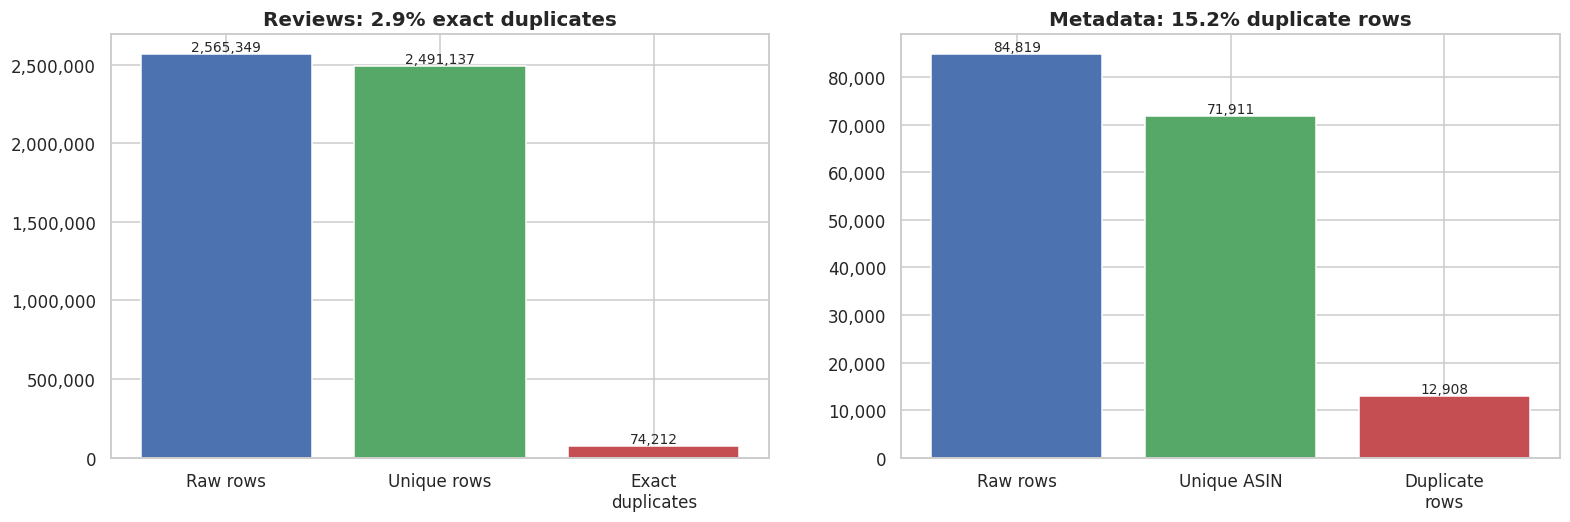

In [16]:
REV_RAW, REV_UNIQUE = 2_565_349, 2_491_137

meta_total  = metadata.count()
meta_unique = metadata.select("asin").distinct().count()

asin_rev  = reviews.select("asin").distinct()
asin_meta = metadata.select("asin").distinct()
n_asin_rev   = asin_rev.count()
n_unmatched  = asin_rev.join(asin_meta, "asin", "left_anti").count()
n_rev_orphan = rv.join(asin_rev.join(asin_meta, "asin", "left_anti"), "asin").count()

fig, ax = plt.subplots(1, 2, figsize=(17, 5))

# (a) review duplicates
vals = [REV_RAW, REV_UNIQUE, REV_RAW - REV_UNIQUE]
b = ax[0].bar(["Raw rows", "Unique rows", "Exact\nduplicates"], vals, color=["#4c72b0", "#55a868", "#c44e52"])
for r, v in zip(b, vals):
    ax[0].text(r.get_x() + r.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax[0].yaxis.set_major_formatter(fmt_int)
ax[0].set_title(f"Reviews: {(REV_RAW-REV_UNIQUE)/REV_RAW*100:.1f}% exact duplicates")

# (b) metadata duplicates
vals = [meta_total, meta_unique, meta_total - meta_unique]
b = ax[1].bar(["Raw rows", "Unique ASIN", "Duplicate\nrows"], vals, color=["#4c72b0", "#55a868", "#c44e52"])
for r, v in zip(b, vals):
    ax[1].text(r.get_x() + r.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax[1].yaxis.set_major_formatter(fmt_int)
ax[1].set_title(f"Metadata: {(meta_total-meta_unique)/meta_total*100:.1f}% duplicate rows")

# (c) ASIN coverage
vals = [n_asin_rev - n_unmatched, n_unmatched]
ax[2].pie(vals, labels=[f"Has metadata\n({vals[0]:,})", f"No metadata\n({vals[1]:,})"],
          colors=["#55a868", "#c44e52"], startangle=90, explode=(0, 0.12),
          wedgeprops=dict(width=0.5, edgecolor="white"))
ax[2].set_title(f"ASIN coverage ({vals[0]/n_asin_rev*100:.2f}%) | {n_rev_orphan:,} orphan reviews")
save("01_data_quality_overview")

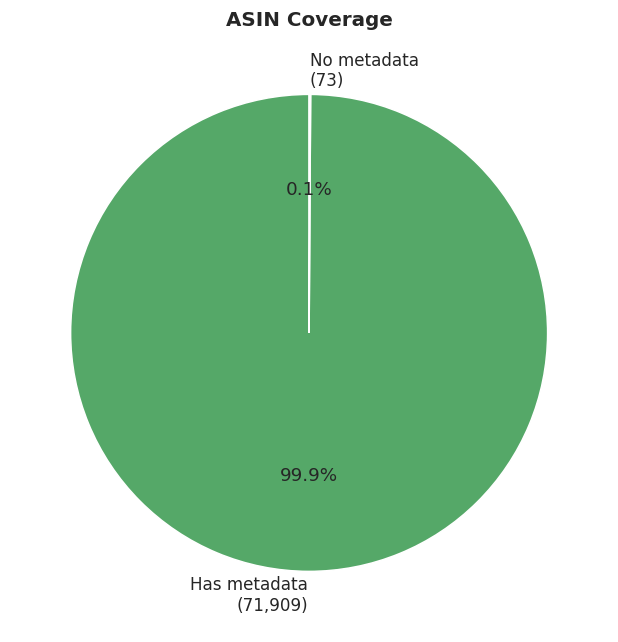

In [20]:
vals = [n_asin_rev - n_unmatched, n_unmatched]

plt.figure(figsize=(6, 6))
plt.pie(
    vals,
    labels=[
        f"Has metadata\n({vals[0]:,})",
        f"No metadata\n({vals[1]:,})"
    ],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#55a868", "#c44e52"]
)

plt.title("ASIN Coverage")
plt.tight_layout()

save("asin_coverage")
plt.show()

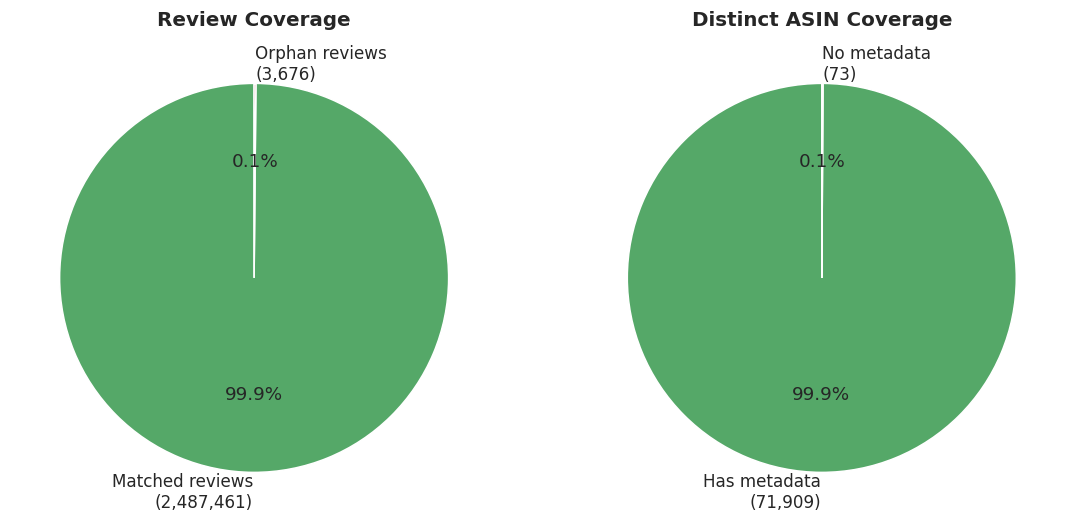

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

vals = [REV_UNIQUE - n_rev_orphan, n_rev_orphan]
ax[0].pie(
    vals,
    labels=[
        f"Matched reviews\n({vals[0]:,})",
        f"Orphan reviews\n({vals[1]:,})"
    ],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#55a868", "#c44e52"]
)
ax[0].set_title("Review Coverage")

vals = [n_asin_rev - n_unmatched, n_unmatched]
ax[1].pie(
    vals,
    labels=[
        f"Has metadata\n({vals[0]:,})",
        f"No metadata\n({vals[1]:,})"
    ],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#55a868", "#c44e52"]
)
ax[1].set_title("Distinct ASIN Coverage")

plt.tight_layout()
save("02_coverage")
plt.show()

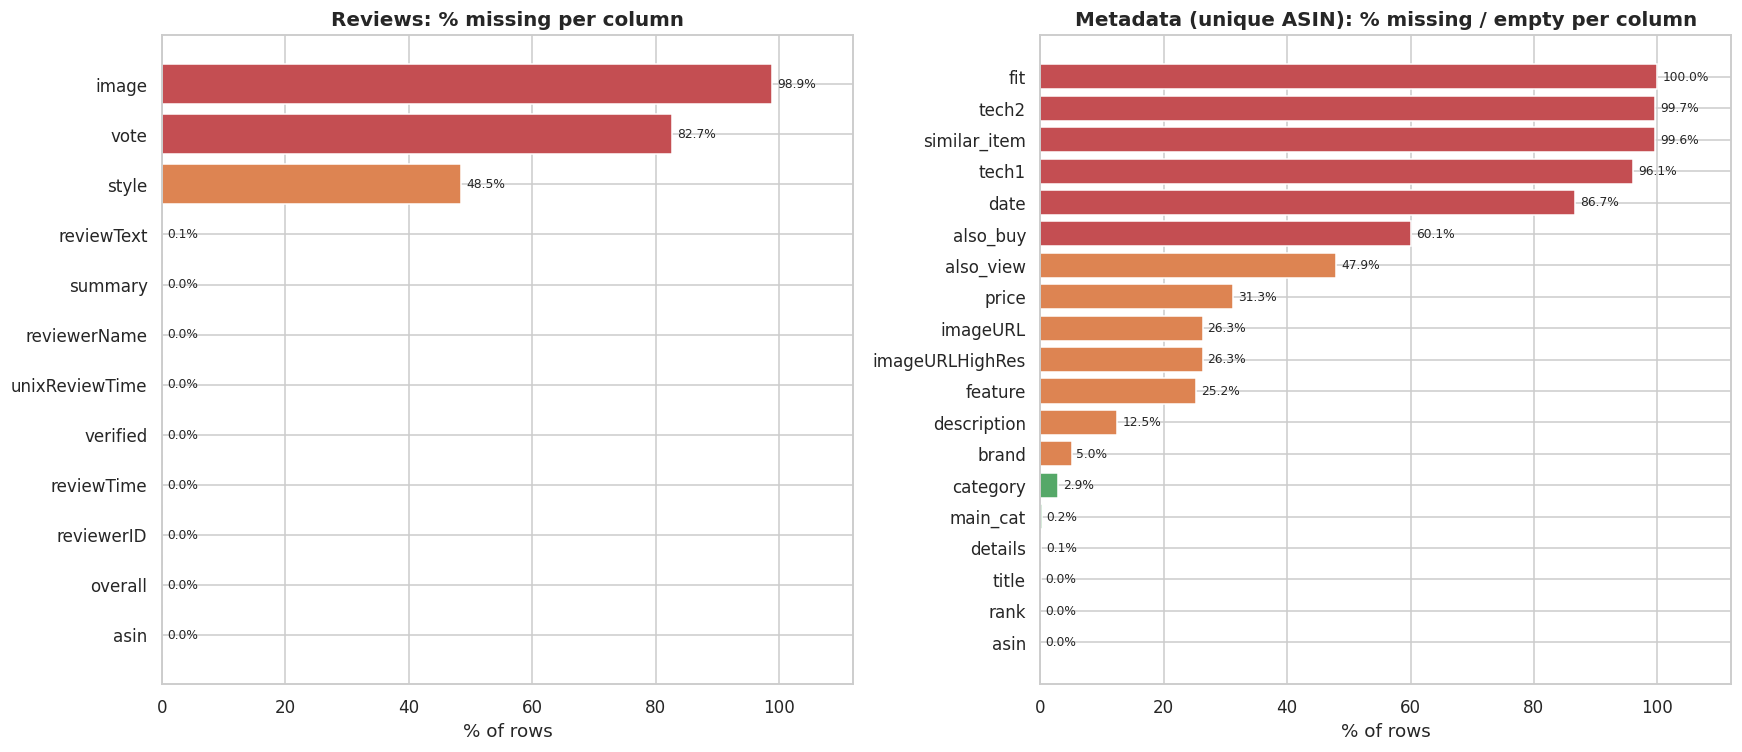

In [18]:
# Missing values: reviews (raw) and metadata (unique ASIN; empty strings / empty arrays count as missing)
miss_rv = reviews.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in reviews.columns]).toPandas().iloc[0]
miss_rv = (miss_rv / total_reviews * 100).sort_values()

def is_missing(c, dtype):
    if dtype.startswith("array"):
        return F.col(c).isNull() | (F.size(c) == 0)
    if dtype == "string":
        return F.col(c).isNull() | (F.trim(F.col(c)) == "")
    return F.col(c).isNull()

meta_u = metadata.dropDuplicates(["asin"])
n_meta_u = meta_u.count()
miss_md = meta_u.select([F.sum(is_missing(c, t).cast("int")).alias(c) for c, t in meta_u.dtypes]).toPandas().iloc[0]
miss_md = (miss_md / n_meta_u * 100).sort_values()

def severity_color(p):
    return "#c44e52" if p > 50 else "#dd8452" if p > 5 else "#55a868"

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, s, ttl in [(ax[0], miss_rv, "Reviews: % missing per column"),
                  (ax[1], miss_md, "Metadata (unique ASIN): % missing / empty per column")]:
    a.barh(s.index, s.values, color=[severity_color(p) for p in s.values])
    for y, p in enumerate(s.values):
        a.text(p + 0.8, y, f"{p:.1f}%", va="center", fontsize=8)
    a.set_xlim(0, 112)
    a.set_title(ttl)
    a.set_xlabel("% of rows")
save("02_missing_values")

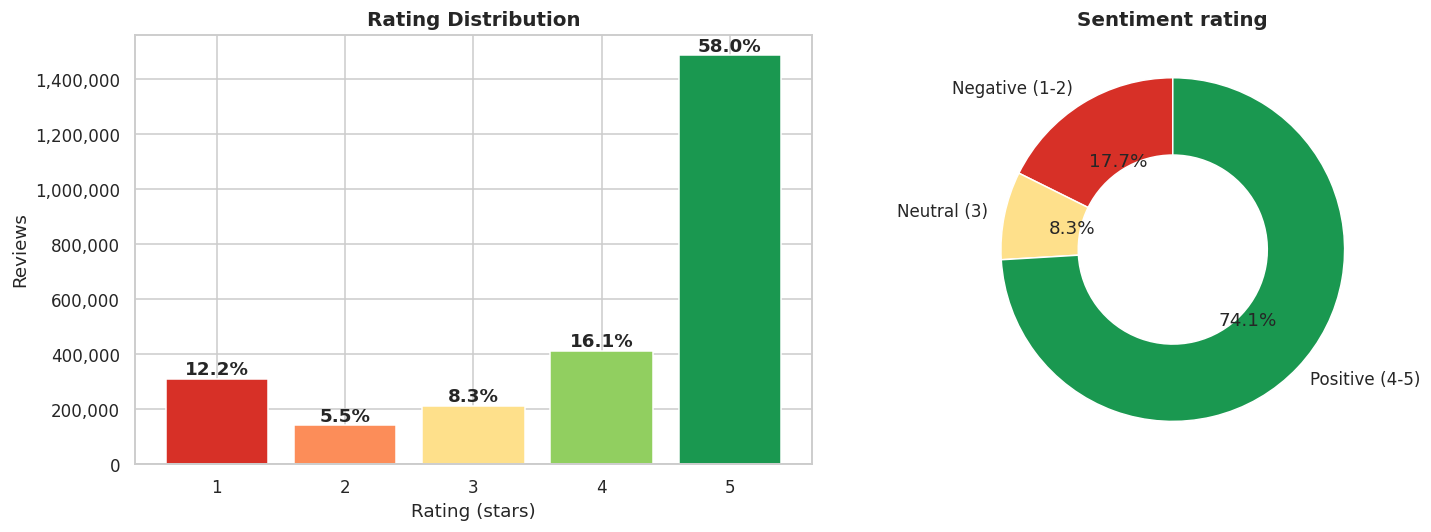

In [15]:
rating_pd = rv.groupBy("overall").count().orderBy("overall").toPandas()
rating_pd["pct"] = rating_pd["count"] / rating_pd["count"].sum() * 100
labels = rating_pd["overall"].astype(int).astype(str)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
bars = ax[0].bar(labels, rating_pd["count"], color=RATING_COLORS, edgecolor="white")
for b, p in zip(bars, rating_pd["pct"]):
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{p:.1f}%", ha="center", va="bottom", fontweight="bold")
ax[0].yaxis.set_major_formatter(fmt_int)
ax[0].set(title="Rating Distribution", xlabel="Rating (stars)", ylabel="Reviews")

c = rating_pd.set_index("overall")["count"]
sent = pd.Series({"Negative (1-2)": c[1.0] + c[2.0], "Neutral (3)": c[3.0], "Positive (4-5)": c[4.0] + c[5.0]})
ax[1].pie(sent, labels=sent.index, autopct="%1.1f%%", startangle=90,
          colors=["#d73027", "#fee08b", "#1a9850"], wedgeprops=dict(width=0.45, edgecolor="white"))
ax[1].set_title("Sentiment rating")
save("03_rating_distribution")

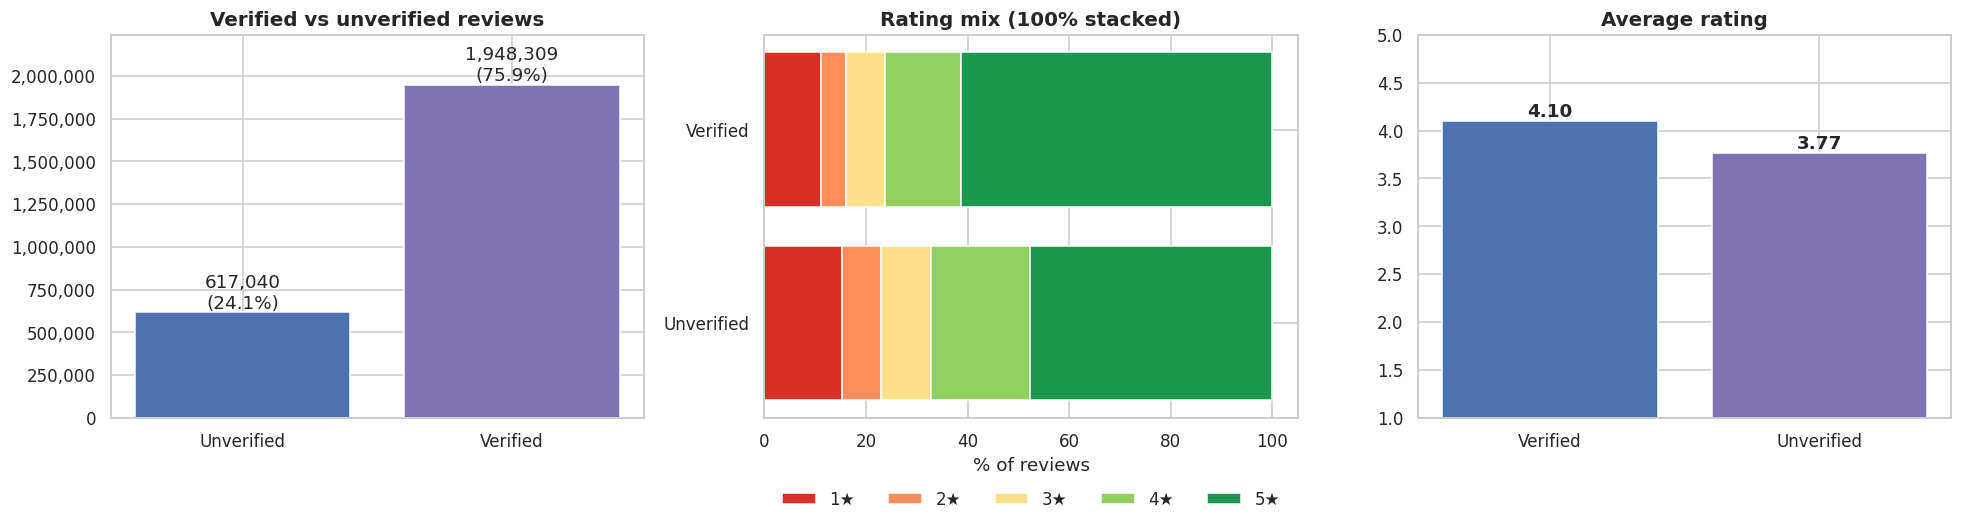

In [11]:
# Verified vs unverified purchases
ver = rv.groupBy("verified", "overall").count().toPandas()
piv = ver.pivot(index="verified", columns="overall", values="count").fillna(0)
piv.index = piv.index.map({True: "Verified", False: "Unverified"})
pct = piv.div(piv.sum(axis=1), axis=0) * 100
avg_by_ver = rv.groupBy("verified").agg(F.avg("overall").alias("avg")).toPandas().set_index("verified")["avg"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
tot = piv.sum(axis=1)
ax[0].bar(tot.index, tot.values, color=["#4c72b0", "#8172b3"])
for i, v in enumerate(tot.values):
    ax[0].text(i, v, f"{v:,.0f}\n({v/tot.sum()*100:.1f}%)", ha="center", va="bottom")
ax[0].yaxis.set_major_formatter(fmt_int)
ax[0].set_title("Verified vs unverified reviews")
ax[0].set_ylim(0, tot.max() * 1.15)

left = np.zeros(len(pct))
for r, col_ in zip(pct.columns, RATING_COLORS):
    ax[1].barh(pct.index, pct[r], left=left, color=col_, label=f"{int(r)}★")
    left += pct[r].values
ax[1].set_title("Rating mix (100% stacked)")
ax[1].set_xlabel("% of reviews")
ax[1].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)

ax[2].bar(["Verified", "Unverified"], [avg_by_ver[True], avg_by_ver[False]], color=["#4c72b0", "#8172b3"])
for i, v in enumerate([avg_by_ver[True], avg_by_ver[False]]):
    ax[2].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontweight="bold")
ax[2].set_ylim(1, 5)
ax[2].set_title("Average rating")
save("04_verified_vs_unverified")

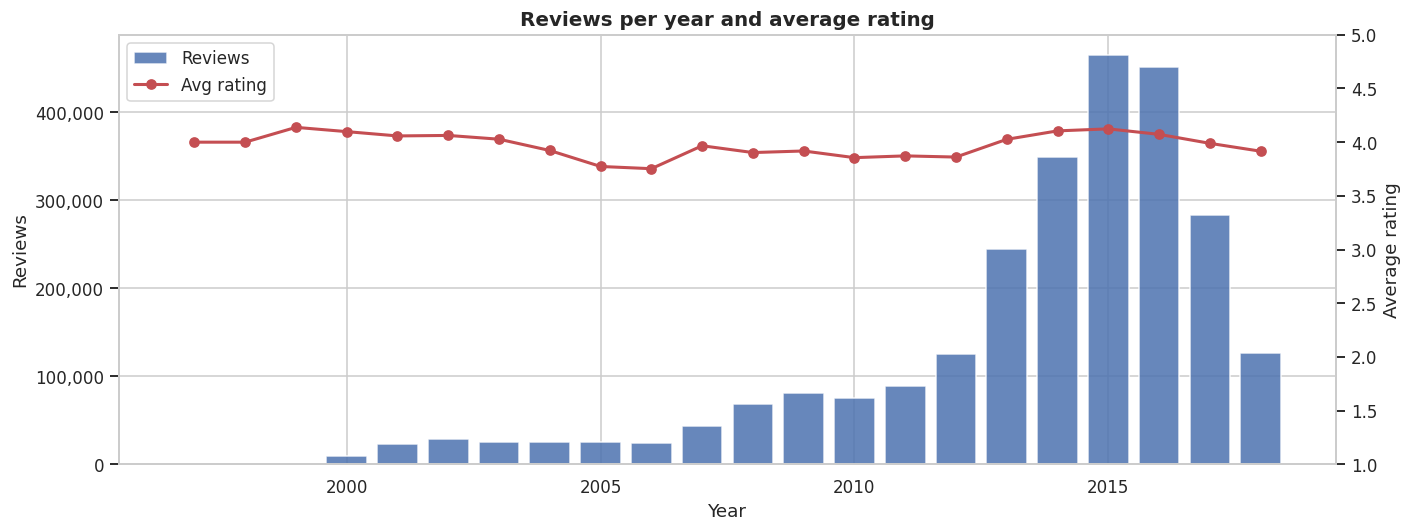

In [12]:
yr = rv.groupBy("year").agg(F.count("*").alias("n"), F.avg("overall").alias("avg_rating")).orderBy("year").toPandas()

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(yr["year"], yr["n"], color="#4c72b0", alpha=0.85, label="Reviews")
ax.yaxis.set_major_formatter(fmt_int)
ax.set(title="Reviews per year and average rating", xlabel="Year", ylabel="Reviews")
ax2 = ax.twinx()
ax2.plot(yr["year"], yr["avg_rating"], color="#c44e52", marker="o", lw=2, label="Avg rating")
ax2.set_ylim(1, 5)
ax2.set_ylabel("Average rating")
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
save("05_reviews_per_year")

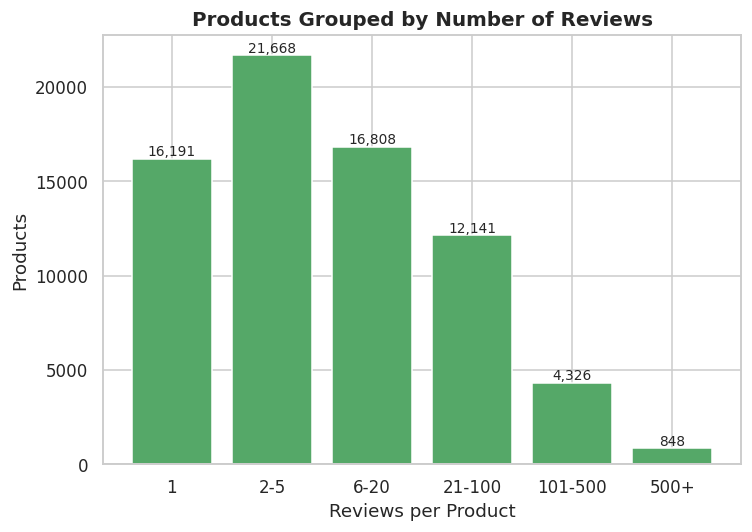

In [25]:
prod = rv.groupBy("asin").agg(F.count("*").alias("n_reviews")).toPandas()

edges = [0, 1, 5, 20, 100, 500, np.inf]
names = ["1", "2-5", "6-20", "21-100", "101-500", "500+"]

cnt = pd.cut(
    prod["n_reviews"],
    bins=edges,
    labels=names
).value_counts().reindex(names)

plt.figure(figsize=(7, 5))

plt.bar(names, cnt.values, color="#55a868")

for i, v in enumerate(cnt.values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

plt.title("Products Grouped by Number of Reviews")
plt.xlabel("Reviews per Product")
plt.ylabel("Products")

plt.tight_layout()
save("11_product_review_groups")
plt.show()

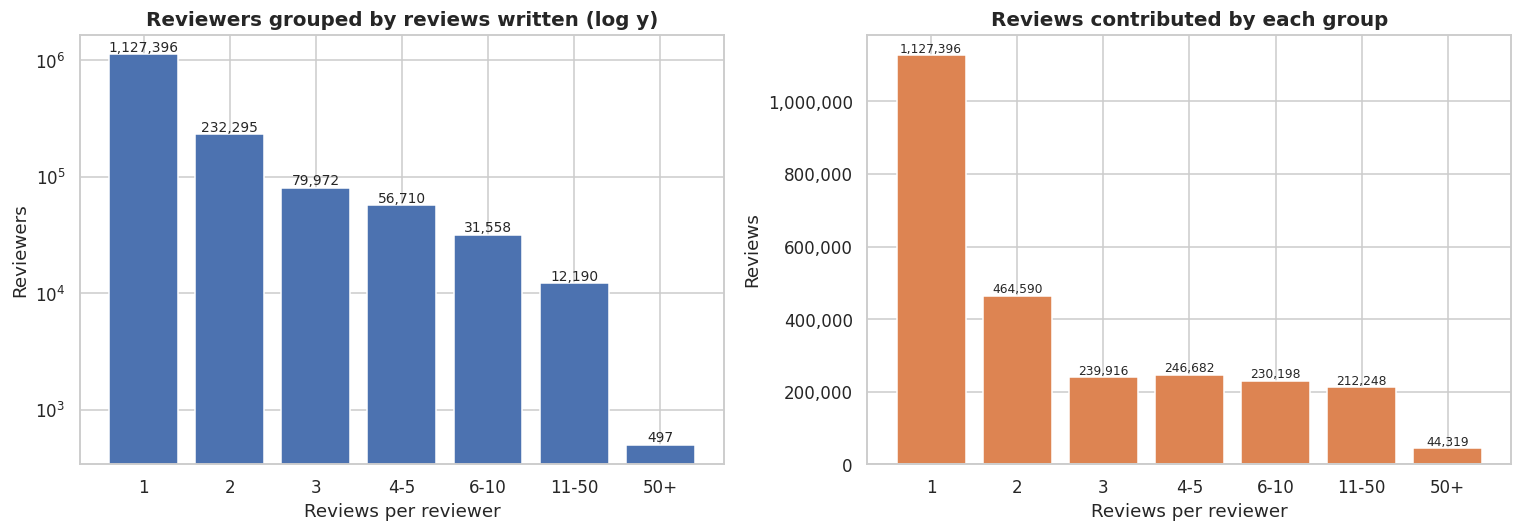

In [26]:
n = F.col("n")
rev_b = (
    rv.groupBy("reviewerID").agg(F.count("*").alias("n"))
      .withColumn("bucket",
                  F.when(n == 1, "1").when(n == 2, "2").when(n == 3, "3").when(n <= 5, "4-5")
                   .when(n <= 10, "6-10").when(n <= 50, "11-50").otherwise("50+"))
      .groupBy("bucket").agg(F.count("*").alias("reviewers"), F.sum("n").alias("reviews"))
      .toPandas()
)
order = ["1", "2", "3", "4-5", "6-10", "11-50", "50+"]
rev_b = rev_b.set_index("bucket").reindex(order)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(order, rev_b["reviewers"], color="#4c72b0")
ax[0].set_yscale("log")
for i, v in enumerate(rev_b["reviewers"]):
    ax[0].text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
ax[0].set(title="Reviewers grouped by reviews written (log y)", xlabel="Reviews per reviewer", ylabel="Reviewers")

ax[1].bar(order, rev_b["reviews"], color="#dd8452")
ax[1].yaxis.set_major_formatter(fmt_int)
for i, v in enumerate(rev_b["reviews"]):
    ax[1].text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=8)
ax[1].set(title="Reviews contributed by each group", xlabel="Reviews per reviewer", ylabel="Reviews")
save("13_reviewer_activity")

In [27]:
price_str = F.regexp_replace(F.regexp_extract("price", r"\$\s?([0-9][0-9,]*\.?[0-9]*)", 1), ",", "")

md_s = (
    metadata.dropDuplicates(["asin"])
    .withColumn("brand_clean", F.trim(F.regexp_replace("brand", r"^\s*by\s+", "")))
    .withColumn("brand_clean", F.when(F.col("brand_clean").isNull() | (F.col("brand_clean") == ""), "Unknown")
                                .otherwise(F.col("brand_clean")))
    .withColumn("main_cat_clean",
                F.when(F.col("main_cat").isNull() | (F.trim("main_cat") == ""), "Unknown")
                 .when(F.col("main_cat").startswith("<img"), "Other (HTML junk)")
                 .otherwise(F.regexp_replace("main_cat", "&amp;", "&")))
    .withColumn("platform", F.coalesce(F.try_element_at("category", F.lit(2)), F.lit("Unknown")))
    .withColumn("price_num", F.when(price_str != "", price_str.cast("double")))
    .withColumn("n_also_buy", F.coalesce(F.size("also_buy"), F.lit(0)))
    .withColumn("n_also_view", F.coalesce(F.size("also_view"), F.lit(0)))
    .withColumn("cat_depth", F.coalesce(F.size("category"), F.lit(0)))
    .select("asin", "title", "brand_clean", "main_cat_clean", "platform", "price_num",
            "n_also_buy", "n_also_view", "cat_depth")
    .persist(StorageLevel.MEMORY_AND_DISK)
)
md_pd = md_s.toPandas()          # ~72k rows, small
print(f"{len(md_pd):,} unique products in metadata")
md_pd.head()

[Stage 171:=============================================>      (176 + 17) / 200]

71,911 unique products in metadata


,asin,title,brand_clean,main_cat_clean,platform,price_num,n_also_buy,n_also_view,cat_depth
0,0439394422,school house rock america rock,Creative Wonders,Video Games,PC,NaN,1,1,4
1,0763030945,Barbie Storymaker Cd Rom,Unknown,Books,PC,1.90,0,0,3
2,3866811713,Deep Fritz 11 Chess Playing Software for PC,ChessBase,Video Games,PC,23.69,0,0,2
3,B00000K1XN,WWF Attitude,Acclaim Sports,Video Games,Retro Gaming & Microconsoles,54.99,69,28,4
4,B00001OX40,Neo Cherry Master,SNK,Video Games,Retro Gaming & Microconsoles,NaN,0,0,4


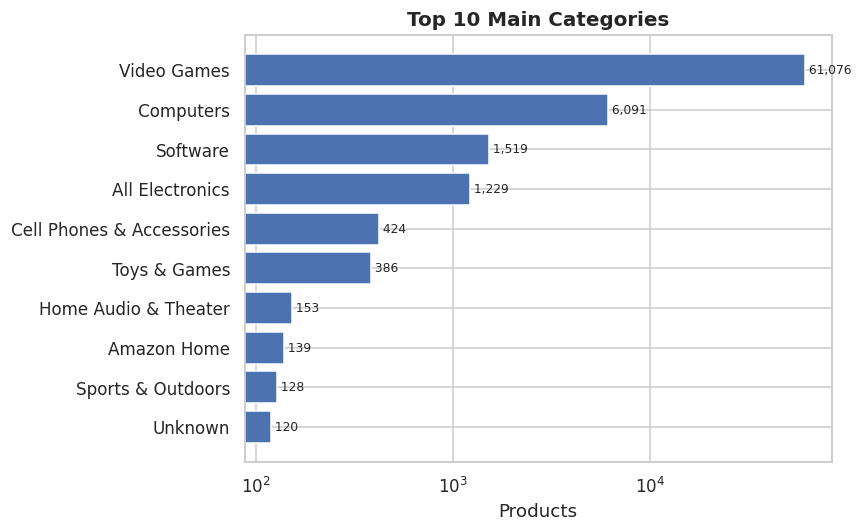

In [29]:
mc = md_pd["main_cat_clean"].value_counts().head(10).sort_values()

plt.figure(figsize=(8, 5))

plt.barh(mc.index, mc.values, color="#4c72b0")
plt.xscale("log")

for y, v in enumerate(mc.values):
    plt.text(v, y, f" {v:,}", va="center", fontsize=8)

plt.title("Top 10 Main Categories")
plt.xlabel("Products")

plt.tight_layout()
save("17_top_main_categories")
plt.show()

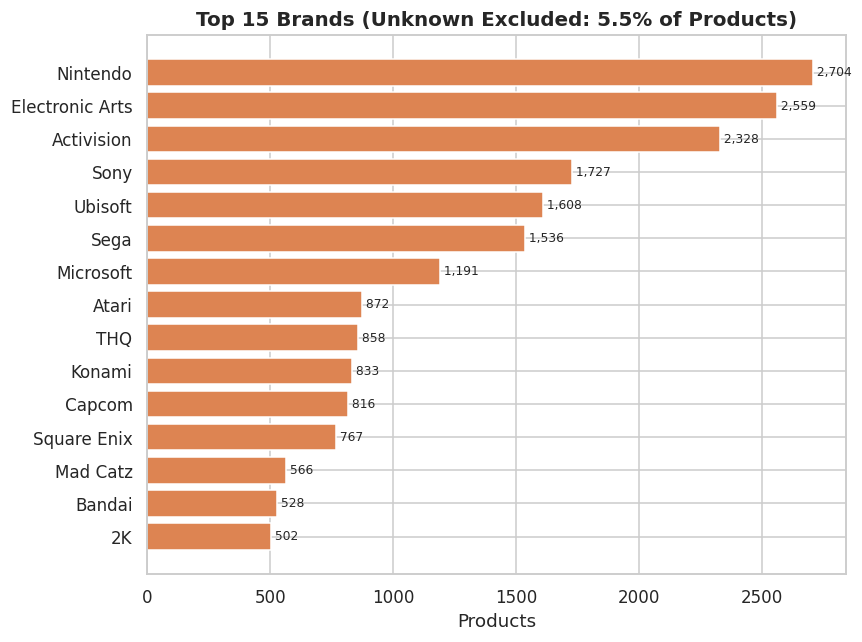

In [30]:
br = (
    md_pd.loc[md_pd["brand_clean"] != "Unknown", "brand_clean"]
    .value_counts()
    .head(15)
    .sort_values()
)

unk = (md_pd["brand_clean"] == "Unknown").mean() * 100

plt.figure(figsize=(8, 6))

plt.barh(br.index, br.values, color="#dd8452")

for y, v in enumerate(br.values):
    plt.text(v, y, f" {v:,}", va="center", fontsize=8)

plt.title(f"Top 15 Brands (Unknown Excluded: {unk:.1f}% of Products)")
plt.xlabel("Products")

plt.tight_layout()
save("18_top_brands")
plt.show()

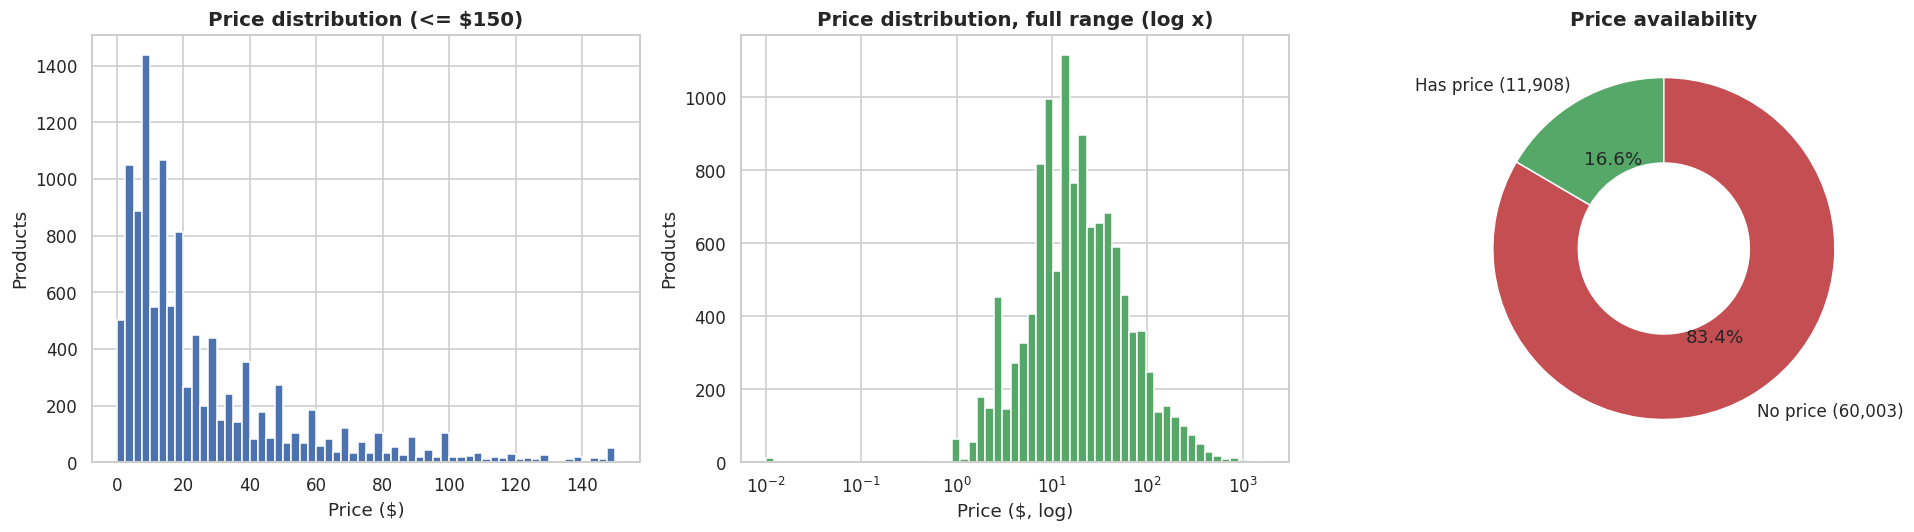

In [31]:
p = md_pd["price_num"]
p_pos = p[p > 0]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].hist(p_pos[p_pos <= 150], bins=60, color="#4c72b0", edgecolor="white")
ax[0].set(title="Price distribution (<= $150)", xlabel="Price ($)", ylabel="Products")

ax[1].hist(p_pos, bins=np.logspace(np.log10(max(p_pos.min(), 0.01)), np.log10(p_pos.max()), 60),
           color="#55a868", edgecolor="white")
ax[1].set_xscale("log")
ax[1].set(title="Price distribution, full range (log x)", xlabel="Price ($, log)", ylabel="Products")

ax[2].pie([p.notna().sum(), p.isna().sum()],
          labels=[f"Has price ({p.notna().sum():,})", f"No price ({p.isna().sum():,})"],
          colors=["#55a868", "#c44e52"], autopct="%1.1f%%", startangle=90,
          wedgeprops=dict(width=0.5, edgecolor="white"))
ax[2].set_title("Price availability")
save("18_price_analysis")

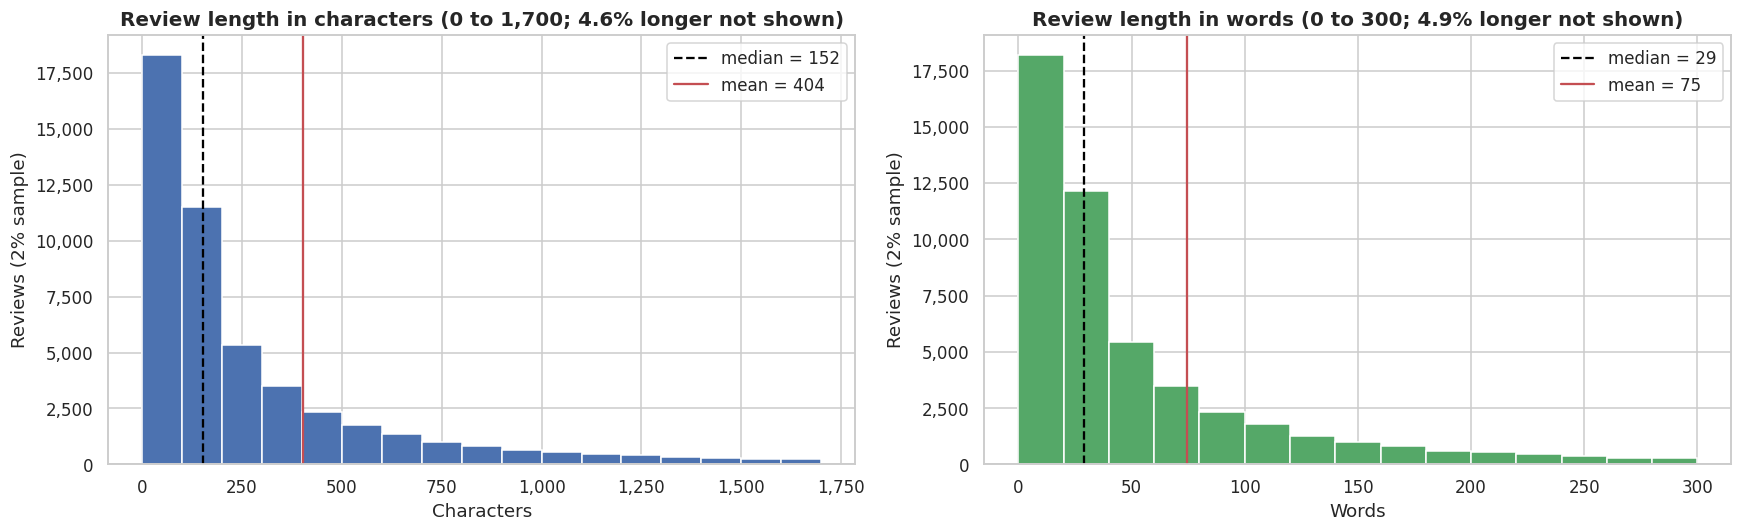

In [9]:
len_s = (rv.where(F.col("text_len") > 0).select("text_len", "word_count")
           .sample(False, 0.02, seed=42).toPandas())          # ~50k rows sample for the shape

def cap_and_plot(ax, s, color, unit, step):
    cap = int(np.ceil(s.quantile(0.95) / step) * step)       # 95th percentile rounded up to a nice number
    shown = s[s <= cap]
    ax.hist(shown, bins=np.arange(0, cap + step, step), color=color, edgecolor="white")
    ax.axvline(s.median(), color="black", ls="--", lw=1.5, label=f"median = {s.median():,.0f}")
    ax.axvline(s.mean(), color="#c44e52", ls="-", lw=1.5, label=f"mean = {s.mean():,.0f}")
    ax.legend()
    ax.xaxis.set_major_formatter(fmt_int)
    ax.yaxis.set_major_formatter(fmt_int)
    ax.set(title=f"Review length in {unit} (0 to {cap:,}; {(s > cap).mean()*100:.1f}% longer not shown)",
           xlabel=unit.capitalize(), ylabel="Reviews (2% sample)")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
cap_and_plot(ax[0], len_s["text_len"], "#4c72b0", "characters", 100)
cap_and_plot(ax[1], len_s["word_count"], "#55a868", "words", 20)
save("09_review_length")

In [8]:
# Descriptive statistics of review length (non-empty reviews, full data)
(rv.where(F.col("text_len") > 0)
   .select("text_len", "word_count")
   .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "90%", "99%", "max")
   .toPandas())

,summary,text_len,word_count
0,count,2563634,2563634
1,mean,401.0472458237018,74.14570293575449
2,stddev,811.3024772706987,146.2198222655199
3,min,1,1
4,25%,55,10
5,50%,151,29
6,75%,398,75
7,90%,958,177
8,99%,3871,700
9,max,32721,6203


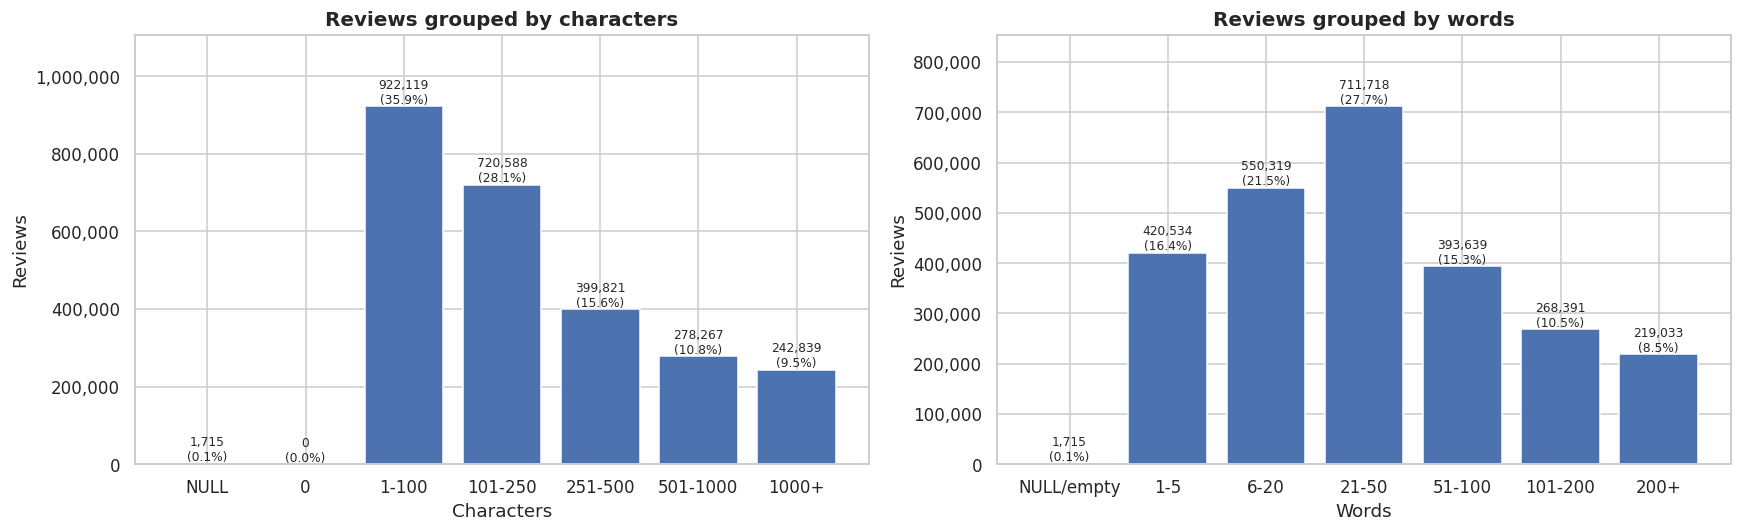

In [9]:
# Length groups on full data (linear axis, exact counts)
char_names = ["0", "1-100", "101-250", "251-500", "501-1000", "1000+"]
char_b = (rv.withColumn("g", F.when(F.col("text_len").isNull(), "NULL")
                              .when(F.col("text_len") == 0, "0")
                              .when(F.col("text_len") <= 100, "1-100")
                              .when(F.col("text_len") <= 250, "101-250")
                              .when(F.col("text_len") <= 500, "251-500")
                              .when(F.col("text_len") <= 1000, "501-1000")
                              .otherwise("1000+"))
            .groupBy("g").count().toPandas().set_index("g").reindex(["NULL"] + char_names).fillna(0))

word_names = ["1-5", "6-20", "21-50", "51-100", "101-200", "200+"]
word_b = (rv.withColumn("g", F.when(F.col("word_count").isNull(), "NULL/empty")
                              .when(F.col("word_count") <= 5, "1-5")
                              .when(F.col("word_count") <= 20, "6-20")
                              .when(F.col("word_count") <= 50, "21-50")
                              .when(F.col("word_count") <= 100, "51-100")
                              .when(F.col("word_count") <= 200, "101-200")
                              .otherwise("200+"))
            .groupBy("g").count().toPandas().set_index("g").reindex(["NULL/empty"] + word_names).fillna(0))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a, d, ttl, xl in [(ax[0], char_b, "Reviews grouped by characters", "Characters"),
                      (ax[1], word_b, "Reviews grouped by words", "Words")]:
    a.bar(d.index, d["count"], color="#4c72b0")
    for i, v in enumerate(d["count"]):
        a.text(i, v, f"{int(v):,}\n({v/d['count'].sum()*100:.1f}%)", ha="center", va="bottom", fontsize=8)
    a.yaxis.set_major_formatter(fmt_int)
    a.set_ylim(0, d["count"].max() * 1.2)
    a.set(title=ttl, xlabel=xl, ylabel="Reviews")
save("09b_review_length_groups")

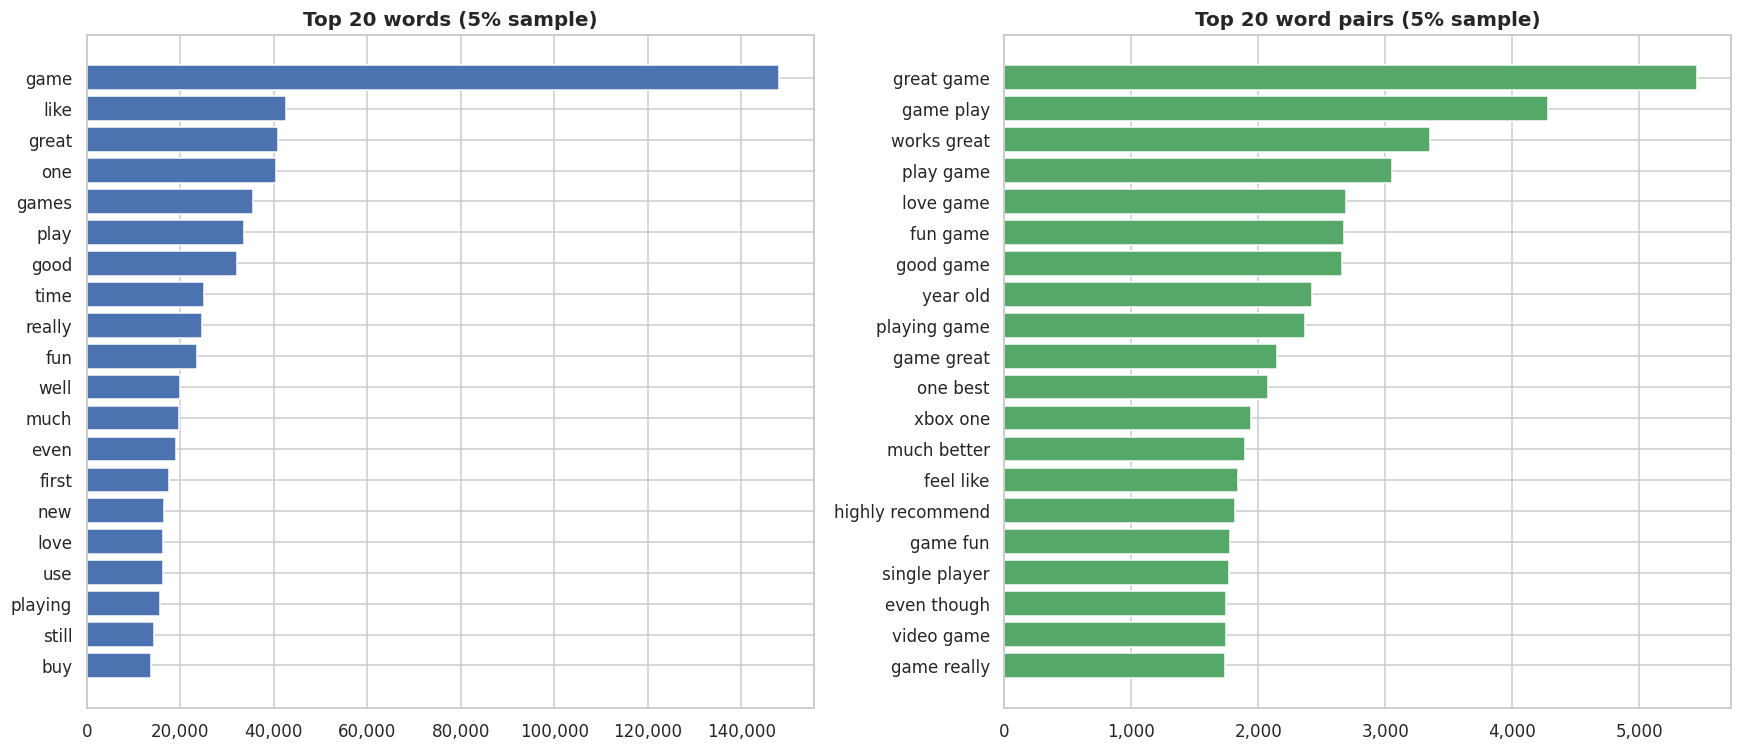

DataFrame[reviewText: string, tokens: array<string>, clean: array<string>]

In [11]:
# Word frequency on a 5% sample (stop words removed; no sentiment split, purely descriptive)
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, NGram

stop_words = StopWordsRemover.loadDefaultStopWords("english") + ["it's", "i'm", "don't", "didn't", "can't", "also", "get", "got"]

txt = (reviews.select("reviewText").where(F.col("reviewText").isNotNull())
              .sample(False, 0.05, seed=42))
tok = RegexTokenizer(inputCol="reviewText", outputCol="tokens", pattern="[^a-z']+", minTokenLength=3, toLowercase=True)
rem = StopWordsRemover(inputCol="tokens", outputCol="clean", stopWords=stop_words)
cl = rem.transform(tok.transform(txt)).cache()

uni = (cl.select(F.explode("clean").alias("w")).groupBy("w").count()
         .orderBy(F.desc("count")).limit(20).toPandas().sort_values("count"))
bi = NGram(n=2, inputCol="clean", outputCol="bi").transform(cl)
bi = (bi.select(F.explode("bi").alias("w")).groupBy("w").count()
        .orderBy(F.desc("count")).limit(20).toPandas().sort_values("count"))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].barh(uni["w"], uni["count"], color="#4c72b0")
ax[0].xaxis.set_major_formatter(fmt_int)
ax[0].set_title("Top 20 words (5% sample)")
ax[1].barh(bi["w"], bi["count"], color="#55a868")
ax[1].xaxis.set_major_formatter(fmt_int)
ax[1].set_title("Top 20 word pairs (5% sample)")
save("09g_top_words_bigrams")
cl.unpersist()

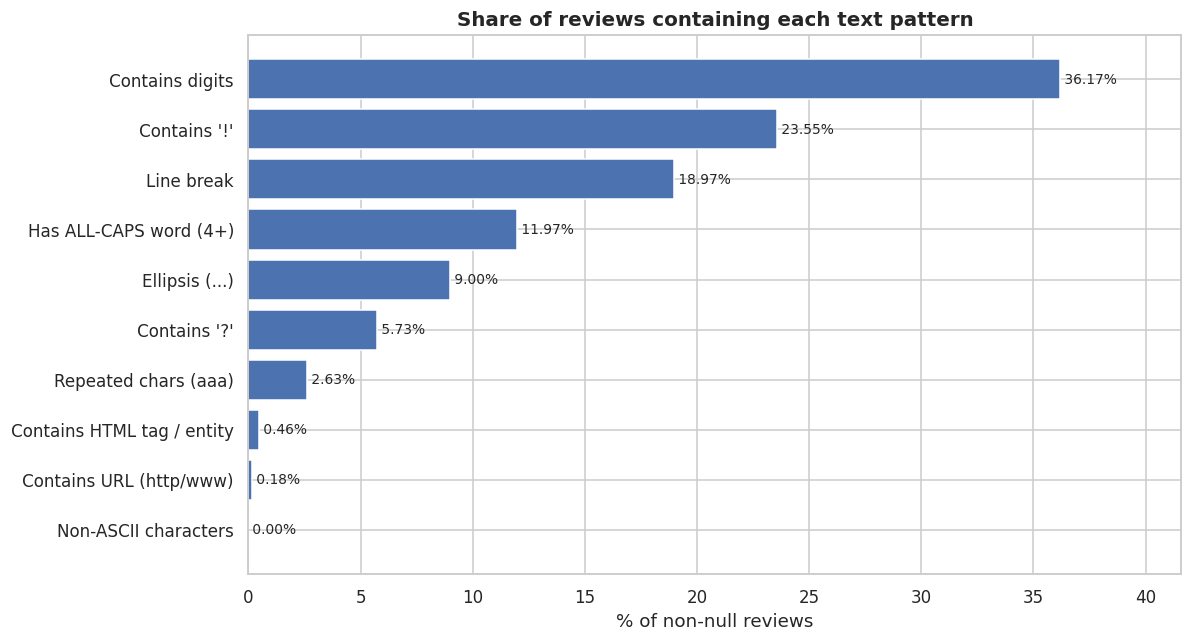

In [12]:
# % of non-null reviews containing each pattern (single pass over the full data)
t = F.col("reviewText")
patterns = {
    "Contains digits":            r"[0-9]",
    "Contains URL (http/www)":    r"(?i)(http|www\.)",
    "Contains HTML tag / entity": r"(<[a-zA-Z/][^>]*>|&#?[a-zA-Z0-9]+;)",
    "Contains '!'":               r"!",
    "Contains '?'":               r"\?",
    "Has ALL-CAPS word (4+)":     r"\b[A-Z]{4,}\b",
    "Non-ASCII characters":       r"[^\x00-\x7F]",
    "Ellipsis (...)":             r"\.{3,}",
    "Repeated chars (aaa)":       r"(\w)\1{2,}",
    "Line break":                 r"[\r\n]",
}
n_text = reviews.where(t.isNotNull()).count()
row = reviews.where(t.isNotNull()).select(
    *[F.sum(t.rlike(p).cast("int")).alias(k) for k, p in patterns.items()]).first().asDict()
feat = (pd.Series(row) / n_text * 100).sort_values()

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(feat.index, feat.values, color="#4c72b0")
for y, v in enumerate(feat.values):
    ax.text(v, y, f" {v:.2f}%", va="center", fontsize=9)
ax.set_xlim(0, max(feat.values) * 1.15)
ax.set(title="Share of reviews containing each text pattern", xlabel="% of non-null reviews")
save("09d_text_patterns")

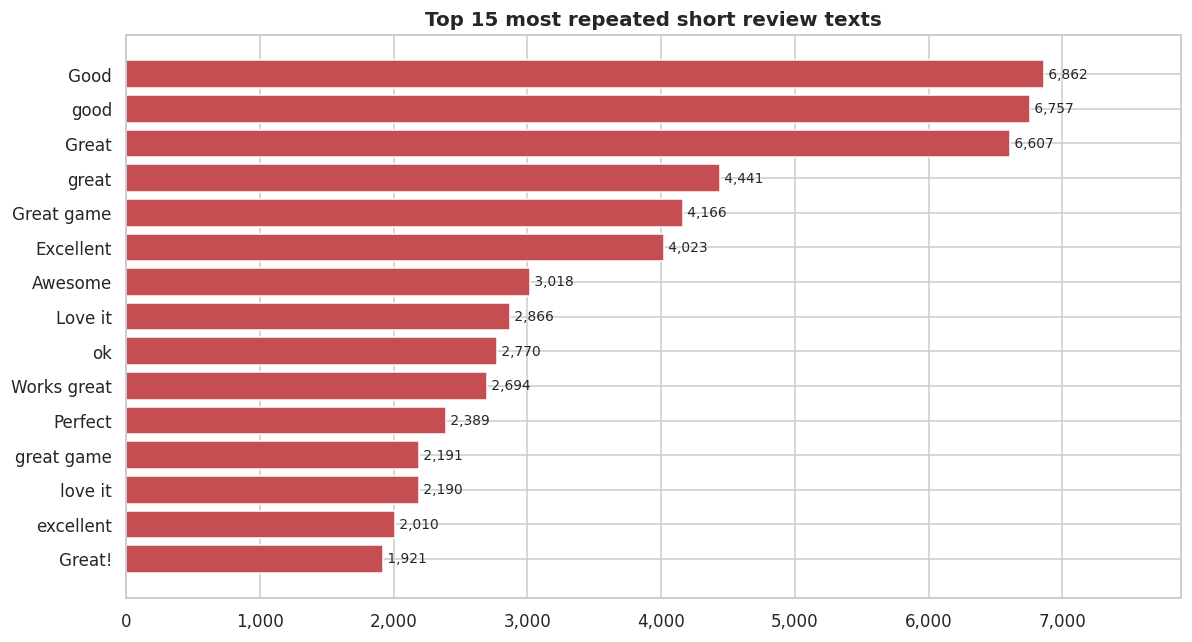

In [13]:
# Most repeated short review texts (<= 80 chars): shows duplicate / templated text
rep = (reviews.where(F.col("reviewText").isNotNull() & (F.length("reviewText") <= 80) & (F.trim("reviewText") != ""))
              .groupBy("reviewText").count()
              .orderBy(F.desc("count")).limit(15).toPandas().sort_values("count"))

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh([html.unescape(s)[:60] for s in rep["reviewText"]], rep["count"], color="#c44e52")
for y, v in enumerate(rep["count"]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(fmt_int)
ax.set_xlim(0, rep["count"].max() * 1.15)
ax.set_title("Top 15 most repeated short review texts")
save("09f_repeated_short_texts")